# Benchmarks

*Speed and region discovery of `pspGlobal()` in psp-torch against the R package, on the same machine, and when the GPU is worth using.*

The R package's [benchmarks article](https://lenarddome.com/psp/articles/benchmarks.html) measured psp 1.0.6 against 1.0.5. This notebook uses the same workloads and the same scripts to measure the R package against the PyTorch port, both run on this machine, and adds a study of CPU against GPU. The results and the scripts that produced them are in [`benchmarks/`](../benchmarks): `compare.py` runs the R scripts and the torch scripts in turn, and `devices.py` times the models on every device.

Three things to keep in mind when reading the numbers:

- **The R package calls the model once per parameter set; the port calls it once per iteration** with every proposal in one batch. For the toy models here that is the whole difference, because the models themselves cost next to nothing. The `rowwise` rows show the port calling the model one parameter set at a time, as R does.
- **Random numbers differ**, so runs with the same seed take different paths. Workloads are compared by their median over seeds.
- **The GPU here is small** (an NVIDIA T400 with 4 GB), and like most consumer cards it is slow in double precision. The device study measures float32 and float64 separately.

In [1]:
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
from matplotlib import patches as mpatches
from matplotlib.lines import Line2D

plt.rcParams.update({
    "figure.figsize": (7, 4.6), "figure.dpi": 110, "savefig.dpi": 150,
    "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.spines.bottom": False, "axes.grid": True, "grid.color": "#e9ecef", "axes.axisbelow": True,
    "axes.labelcolor": "#495057", "xtick.color": "#495057", "ytick.color": "#495057",
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False, "legend.fontsize": 11,
})
blue, grey = "#2a78d6", "#adb5bd"


def titled(ax, title, subtitle=None, pad=0):
    """A bold title and a grey subtitle, both left-aligned, as in the R articles."""
    ax.set_title(title, loc="left", pad=(26 if subtitle else 10) + pad)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6 + pad),
                    textcoords="offset points", color="#6c757d", fontsize=11, va="bottom")
    return ax

results = Path("../benchmarks/results")
read = lambda name: pd.read_csv(results / f"{name}.csv")
workloads = read("workloads")
builds = list(dict.fromkeys(workloads.build))
r_build = next(b for b in builds if not b.startswith("psp-torch"))
torch_builds = [b for b in builds if b.startswith("psp-torch")]
build_colours = dict(zip(builds, ["#6c757d", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7"]))

## Time per run

Each workload ran 3 to 10 times with different seeds; dots show the median wall-clock time of one complete `pspGlobal()` run. The cheap toy models make each package's own overhead visible: with the test-suite model, most of the time is the model itself.

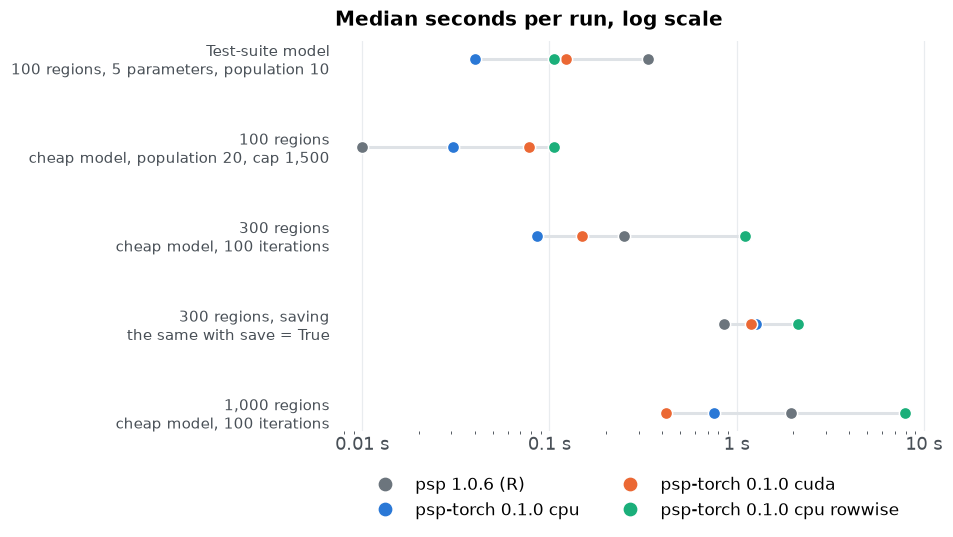

build,psp 1.0.6 (R),psp-torch 0.1.0 cpu,psp-torch 0.1.0 cuda,psp-torch 0.1.0 cpu rowwise,"speed-up, 0.1.0 cpu","speed-up, 0.1.0 cuda","speed-up, 0.1.0 cpu rowwise"
Test-suite model,0.335,0.040,0.123,0.105,8.4×,2.7×,3.2×
100 regions,0.010,0.030,0.078,0.106,0.3×,0.1×,0.1×
300 regions,0.250,0.086,0.150,1.104,2.9×,1.7×,0.2×
"300 regions, saving",0.860,1.268,1.190,2.117,0.7×,0.7×,0.4×
"1,000 regions",1.950,0.759,0.422,7.896,2.6×,4.6×,0.2×


In [2]:
order = list(dict.fromkeys(workloads.workload))
details = {
    "test model, pop 10": ("Test-suite model", "100 regions, 5 parameters, population 10"),
    "100 regions, pop 20, cap 1500": ("100 regions", "cheap model, population 20, cap 1,500"),
    "300 regions, 100 iterations": ("300 regions", "cheap model, 100 iterations"),
    "300 regions, 100 iterations, save": ("300 regions, saving", "the same with save = True"),
    "1000 regions, 100 iterations": ("1,000 regions", "cheap model, 100 iterations"),
}
median = workloads.groupby(["workload", "build"]).seconds.median().unstack()[builds].loc[order]
fig, ax = plt.subplots(figsize=(7, 4.6))
ys = np.arange(len(order))[::-1]
for y, w in zip(ys, order):
    row = median.loc[w]
    ax.plot([row.min(), row.max()], [y, y], color="#dee2e6", linewidth=2, zorder=1)
    for b in builds:
        ax.plot(row[b], y, "o", markersize=8, color=build_colours[b], markeredgecolor="white", zorder=2)
ax.set_xscale("log")
ax.set_yticks(ys, [f"{details[w][0]}\n{details[w][1]}" for w in order], fontsize=10)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g} s")
ax.grid(axis="y", visible=False)
handles = [Line2D([], [], marker="o", linestyle="", markersize=8, color=build_colours[b], label=b) for b in builds]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
titled(ax, "Median seconds per run, log scale")
plt.show()
table = median.copy()
for b in torch_builds:
    table[f"speed-up, {b.replace('psp-torch ', '')}"] = (median[r_build] / median[b]).map(lambda x: f"{x:.1f}×")
table.index = [details[w][0] for w in order]
table.round(3)

These are whole runs: the time from calling `pspGlobal()` to getting its result back, including every model evaluation. They are short because the workloads are small and the models cost microseconds. Per workload, the median number of iterations and evaluations a run took, and what that makes one evaluation cost in each build:

In [3]:
size = workloads.groupby(["workload", "build"]).agg(iterations=("iterations", "median"), evaluations=("evaluations", "median"), seconds=("seconds", "median"))
per_evaluation = (1e6 * size.seconds / size.evaluations).unstack()[builds].loc[order]
context = pd.DataFrame({
    "Median iterations": size.iterations.unstack()[r_build].loc[order].map(lambda v: f"{v:,.0f}"),
    "Median evaluations": size.evaluations.unstack()[r_build].loc[order].map(lambda v: f"{v:,.0f}"),
    **{f"µs per evaluation, {b}": per_evaluation[b].round(1) for b in builds},
})
context.index = [details[w][0] for w in order]
context

,Median iterations,Median evaluations,"µs per evaluation, psp 1.0.6 (R)","µs per evaluation, psp-torch 0.1.0 cpu","µs per evaluation, psp-torch 0.1.0 cuda","µs per evaluation, psp-torch 0.1.0 cpu rowwise"
Test-suite model,136,"1,756",190.7,21.8,67.7,57.4
100 regions,78,"2,235",4.5,13.6,35.1,47.4
300 regions,100,"24,202",10.3,3.6,6.2,46.7
"300 regions, saving",100,"24,202",35.5,53.6,49.5,89.6
"1,000 regions",100,"82,098",23.8,9.3,5.2,96.6


To see one for yourself, this cell runs the 100-region workload once, here and now, and times the whole call:

In [4]:
import time

from psp import pspGlobal
from psp.models.voronoi import voronoi_control, voronoi_model

v = voronoi_model(100, 5)
generator = torch.Generator().manual_seed(1)
start = time.perf_counter()
result = pspGlobal(v.model, v.discretize, voronoi_control(100, 5, 1500, 20), quiet=True, generator=generator)
elapsed = time.perf_counter() - start
print(f"{elapsed:.3f} s for the whole run: {result.iterations} iterations, {result.evaluations:,} evaluations, "
      f"{result.patterns} regions, {1e6 * elapsed / result.evaluations:.1f} µs per evaluation")

0.034 s for the whole run: 100 iterations, 2,200 evaluations, 95 regions, 15.6 µs per evaluation


In [5]:
cpu_build = next(b for b in torch_builds if b.endswith("cpu"))
capped = workloads[workloads.workload == "100 regions, pop 20, cap 1500"].groupby("build")
display(Markdown(f"""
On the 100-region workload, the R package filled every region in {int(capped.filled.sum()[r_build])} of {int(capped.size()[r_build])} runs after a median of {capped.evaluations.median()[r_build]:,.0f} model evaluations; the port on the CPU filled them in {int(capped.filled.sum()[cpu_build])} of {int(capped.size()[cpu_build])} runs after a median of {capped.evaluations.median()[cpu_build]:,.0f}. The samplers are the same algorithm, so the evaluations they need are alike; the time differs because of what each does around them. That workload is also the one place the R package wins: about {capped.iterations.median()[r_build]:.0f} iterations of a few microseconds each, a run so short that per-iteration overhead is all there is, and R's own timer only resolves it to 10 ms. The port's cost per iteration is higher (a few hundred microseconds of Python and tensor dispatch) and its cost per evaluation lower, so it pulls ahead as soon as iterations carry more than a handful of parameter sets.
"""))


On the 100-region workload, the R package filled every region in 5 of 5 runs after a median of 2,235 model evaluations; the port on the CPU filled them in 5 of 5 runs after a median of 2,241. The samplers are the same algorithm, so the evaluations they need are alike; the time differs because of what each does around them. That workload is also the one place the R package wins: about 78 iterations of a few microseconds each, a run so short that per-iteration overhead is all there is, and R's own timer only resolves it to 10 ms. The port's cost per iteration is higher (a few hundred microseconds of Python and tensor dispatch) and its cost per evaluation lower, so it pulls ahead as soon as iterations carry more than a handful of parameter sets.


## Where the time goes

To isolate each package's own cost, this test uses a model that does almost nothing: it returns its parameters, and `discretize` bins them into 1,024 grid cells. The R script times those two functions from a plain R loop and subtracts; the torch script times them one parameter set at a time (`callbacks_us`, the R way) and in one batch per iteration (`batched_us`, the way `pspGlobal()` calls them).

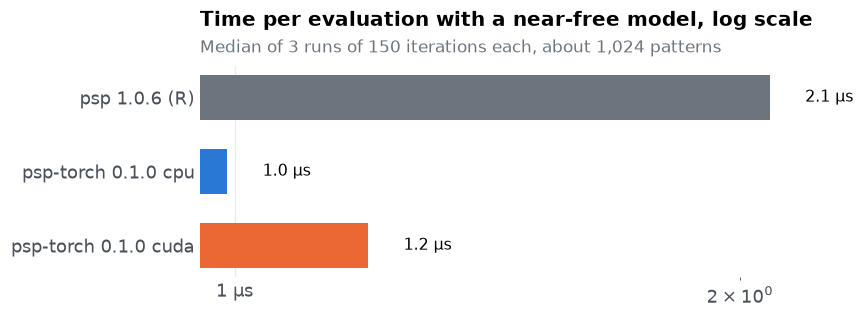

,evaluations,patterns,total_us,callbacks_us,batched_us,framework_us
build,,,,,,
psp 1.0.6 (R),134468.0,1024.0,2.08,2.01,NaN,0.07
psp-torch 0.1.0 cpu,134724.0,1024.0,0.99,16.24,0.01,-15.37
psp-torch 0.1.0 cuda,136324.0,1024.0,1.20,62.60,0.03,-61.44


In [6]:
overhead = read("overhead")
summary = overhead.groupby("build").median(numeric_only=True)
summary = summary.loc[[b for b in builds if b in summary.index]]
fig, ax = plt.subplots(figsize=(7, 1 + 0.5 * len(summary)))
ys = np.arange(len(summary))[::-1]
ax.barh(ys, summary.total_us, color=[build_colours[b] for b in summary.index], height=0.6)
for y, (b, row) in zip(ys, summary.iterrows()):
    ax.text(row.total_us * 1.05, y, f"{row.total_us:.1f} µs", va="center", fontsize=10.5)
ax.set_xscale("log")
ax.set_yticks(ys, summary.index)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g} µs")
ax.grid(axis="y", visible=False)
titled(ax, "Time per evaluation with a near-free model, log scale",
       f"Median of 3 runs of 150 iterations each, about {summary.patterns.iloc[0]:,.0f} patterns")
plt.show()
cols = [c for c in ["evaluations", "patterns", "total_us", "callbacks_us", "batched_us", "framework_us"] if c in summary]
summary[cols].round(2)

`framework_us` is the time per evaluation that is not spent in the two callbacks called one at a time: for R, the package's own bookkeeping; for the port, it is negative, because batching the callbacks saves more than the sampler costs. The port's own cost per iteration is a few hundred microseconds whatever the batch size, so with many patterns filling at once it is spread thin, and with one or two it dominates.

## Saving to disk

With `save=True`, every evaluation writes its parameters and its model outputs, here 300 values, to csv. Both packages write full precision: the R package the shortest text that reads back as the same double (with `std::to_chars`), the port the same through Python's `repr`.

In [7]:
save = read("save").groupby("build").median(numeric_only=True)
save = save.loc[[b for b in builds if b in save.index]]
save[["evaluations", "save_us", "total_us", "mb"]].round(1)

,evaluations,save_us,total_us,mb
build,,,,
psp 1.0.6 (R),24202.0,25.3,34.9,140.3
psp-torch 0.1.0 cpu,23640.0,47.3,51.7,137.0
psp-torch 0.1.0 cuda,24035.0,43.6,48.8,139.3


## Finding regions

Faster is only useful if the search still finds the regions. These are 30 runs per build on a 50-region model with 3 parameters, population 10, radius 0.3 and a 500-iteration cap. The samplers are the same algorithm with different random numbers, so they should find about the same number of regions with about the same number of evaluations.

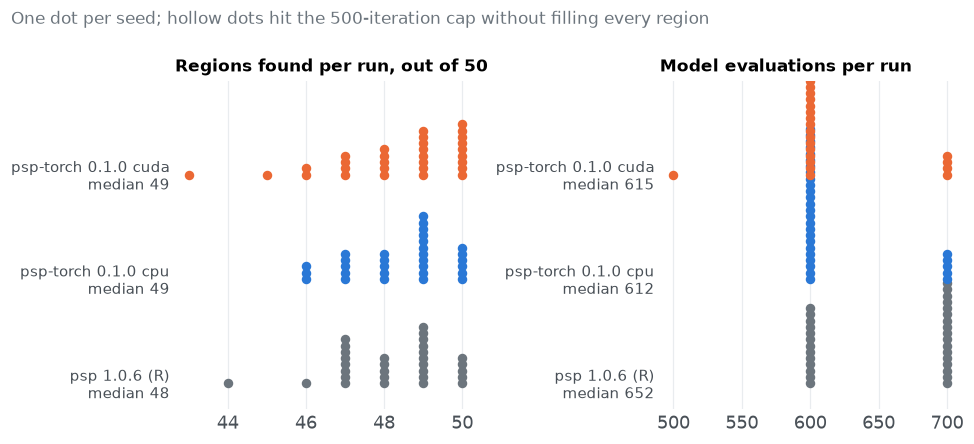

,runs,regions,evaluations,filled
build,,,,
psp 1.0.6 (R),30,48.5,652.0,30
psp-torch 0.1.0 cpu,30,49.0,611.5,30
psp-torch 0.1.0 cuda,30,49.0,615.0,30


In [8]:
discovery = read("discovery")
discovery["filled"] = discovery.filled.astype(str).str.lower().isin(["true", "1"])
present = [b for b in builds if b in set(discovery.build)]
fig, axes = plt.subplots(1, 2, figsize=(9, 1.4 + 0.9 * len(present)))
for ax, key, title in zip(axes, ["regions", "evaluations"], ["Regions found per run, out of 50", "Model evaluations per run"]):
    for i, b in enumerate(present):
        d = discovery[discovery.build == b]
        values = d[key] if key == "regions" else (d[key] / 100).round() * 100
        stacks = {}
        for v, filled in zip(values, d.filled):
            n = stacks.get(v, 0); stacks[v] = n + 1
            ax.plot(v, 2 * i + 0.12 * n, "o", markersize=5, color=build_colours[b] if filled else "white",
                    markeredgecolor=build_colours[b], markeredgewidth=1.2)
    ax.set_yticks([2 * i for i in range(len(present))], [f"{b}\nmedian {discovery[discovery.build == b][key].median():,.0f}" for b in present], fontsize=9.5)
    ax.set_ylim(-0.5, 2 * len(present) - 0.2)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=11)
axes[1].xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
fig.suptitle("One dot per seed; hollow dots hit the 500-iteration cap without filling every region", x=0.02, ha="left",
             fontsize=11, color="#6c757d", fontweight="normal")
fig.tight_layout()
plt.show()
discovery.groupby("build").agg(runs=("seed", "size"), regions=("regions", "median"), evaluations=("evaluations", "median"),
                               filled=("filled", "sum")).loc[present]

PSP never guarantees finding every region. It only finds regions it can reach before every found region is full. The settings below change that, measured on the same model with 30 seeds each:

In [9]:
settings = read("settings")
settings["filled"] = settings.filled.astype(str).str.lower().isin(["true", "1"])
settings = settings[settings.build == cpu_build]
order = list(dict.fromkeys(settings.setting))
table = settings.groupby("setting").agg(
    lo=("regions", "min"), hi=("regions", "max"), median=("regions", "median"),
    all_50=("regions", lambda r: int((r == 50).sum())), runs=("seed", "size"), evaluations=("evaluations", "median"),
).loc[order]
pd.DataFrame({
    "Settings": order,
    "Regions found per run": [f"{int(r.lo)}–{int(r.hi)}, median {r['median']:.0f}" for _, r in table.iterrows()],
    "Runs that found all 50": [f"{int(r.all_50)} of {int(r.runs)}" for _, r in table.iterrows()],
    "Median evaluations": [f"{r.evaluations:,.0f}" for _, r in table.iterrows()],
}).set_index("Settings")

,Regions found per run,Runs that found all 50,Median evaluations
Settings,,,
"1 start, population 10, radius 0.3","46–50, median 49",6 of 30,612
"10 random starts, population 10","43–50, median 49",10 of 30,620
"1 start, population 30","49–50, median 50",29 of 30,"1,728"
"1 start, population 10, radius 0.5","49–50, median 50",26 of 30,726
"10 random starts, population 30","50–50, median 50",30 of 30,"1,750"
"3 pooled runs of 10 starts, population 10","50–50, median 50",30 of 30,"1,862"


Raising `population` helps most. A larger `radius` is cheaper, but in a real model it can jump over small regions. Pooling independent runs is a useful completeness check: if a second run finds a pattern the first missed, the first wasn't complete. The [tutorial](tutorial.ipynb) shows how.

## When is the GPU worth it?

Two things decide whether a run gains from the GPU: how much work one call of `model` does, and how many parameter sets each call receives, which in a PSP run is the number of patterns still filling. `devices.py` measures both. First, `model` and `discretize` alone, for batches of 1 to 4,096 parameter sets, with three models: a near-free one (it returns its parameters), the Voronoi model with 1,000 centres (a `(n, 1000)` distance matrix per call), and ALCOVE with 30 simulated learners (256 sequential trials of a small network per call).

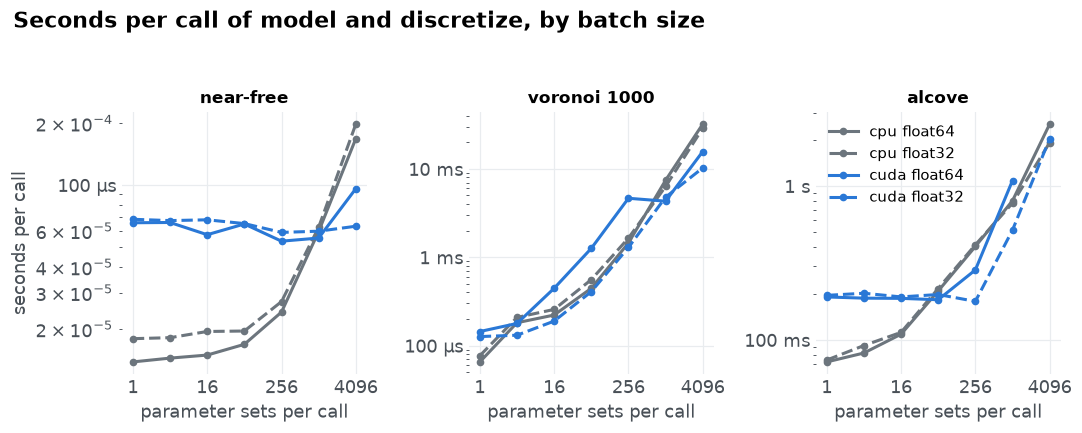

In [10]:
devices = read("devices")
calls = devices[devices.kind == "model"]
models = list(dict.fromkeys(calls.model))
styles = {("cpu", "float64"): ("#6c757d", "-"), ("cpu", "float32"): ("#6c757d", "--"),
          ("cuda", "float64"): ("#2a78d6", "-"), ("cuda", "float32"): ("#2a78d6", "--")}
fig, axes = plt.subplots(1, len(models), figsize=(10, 4), sharey=False)
for ax, m in zip(axes, models):
    for (dev, dt), (colour, style) in styles.items():
        d = calls[(calls.model == m) & (calls.device == dev) & (calls.dtype == dt)].sort_values("batch")
        if len(d):
            ax.plot(d.batch, d.seconds, style, color=colour, linewidth=2, marker="o", markersize=4, label=f"{dev} {dt}")
    ax.set_xscale("log", base=2); ax.set_yscale("log")
    ax.set_title(m, loc="center", fontsize=11)
    ax.set_xlabel("parameter sets per call")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:g} s" if v >= 1 else f"{v * 1000:g} ms" if v >= 1e-3 else f"{v * 1e6:g} µs")
axes[0].set_ylabel("seconds per call")
axes[-1].legend(loc="upper left", fontsize=9.5)
fig.suptitle("Seconds per call of model and discretize, by batch size", x=0.02, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

In [11]:
rows = []
for m in models:
    for dt in ("float32", "float64"):
        cpu = calls[(calls.model == m) & (calls.device == "cpu") & (calls.dtype == dt)].set_index("batch").seconds
        gpu = calls[(calls.model == m) & (calls.device == "cuda") & (calls.dtype == dt)].set_index("batch").seconds
        if len(gpu) == 0:
            continue
        common = cpu.index.intersection(gpu.index)
        faster = [b for b in common if gpu[b] < cpu[b]]
        rows.append({"model": m, "dtype": dt, "GPU faster from batch": min(faster) if faster else "never",
                     "speed-up at largest batch": f"{cpu[common.max()] / gpu[common.max()]:.1f}×"})
crossover = pd.DataFrame(rows)
crossover

,model,dtype,GPU faster from batch,speed-up at largest batch
0,near-free,float32,1024,3.1×
1,near-free,float64,1024,1.8×
2,voronoi 1000,float32,4,2.8×
3,voronoi 1000,float64,4,2.0×
4,alcove,float32,64,0.9×
5,alcove,float64,64,0.7×


Then whole runs of `pspGlobal()` on the same models. The batch size of a run is set here by the number of starting points, with a population that keeps every pattern filling, so the search proposes about as many parameter sets per iteration as it has starts:

In [12]:
runs = devices[devices.kind == "psp"].copy()
runs["per_evaluation_us"] = 1e6 * runs.seconds / runs.evaluations
pivot = runs.pivot_table(index=["model", "batch"], columns=["device", "dtype"], values="seconds")
pivot.round(3)

device                 cpu            cuda        
dtype              float32 float64 float32 float64
model        batch                                
alcove       1       1.712   1.642   3.776   3.880
             16      2.351   2.376   3.932   4.068
near-free    1       0.009   0.010   0.037   0.038
             16      0.015   0.016   0.041   0.043
             256     0.030   0.032   0.052   0.055
voronoi 1000 1       0.021   0.024   0.040   0.042
             16      0.065   0.078   0.057   0.071
             256     0.257   0.302   0.112   0.191

In [13]:
def best_gain(m, dt):
    """Largest CPU/GPU ratio for one model and dtype over the measured batch sizes, and where."""
    cpu = calls[(calls.model == m) & (calls.device == "cpu") & (calls.dtype == dt)].set_index("batch").seconds
    gpu = calls[(calls.model == m) & (calls.device == "cuda") & (calls.dtype == dt)].set_index("batch").seconds
    ratio = (cpu / gpu).dropna()
    return ratio.max(), int(ratio.idxmax())


lines = []
for m in models:
    gain32, at32 = best_gain(m, "float32")
    gain64, at64 = best_gain(m, "float64")
    lines.append(f"- **{m}**: in float32 the GPU is at best {gain32:.1f}× the CPU, at {at32:,} parameter sets per call; "
                 f"in float64 at best {gain64:.1f}×, at {at64:,}.")
alcove_runs = runs[runs.model == "alcove"].pivot_table(index="batch", columns=["device", "dtype"], values="seconds")
display(Markdown(f"""
What the numbers say on this machine:

{chr(10).join(lines)}

- **A model that costs microseconds never gains in a run.** A single call of the near-free model does win once the batch is in the thousands, but a PSP run never proposes that many at once, and every iteration costs a handful of kernel launches and a copy of the patterns back to the CPU, about as much as a whole iteration costs on the CPU. Its runs are slower on the GPU at every batch size.
- **A model that does real tensor work per parameter set gains once each call carries enough of them**, here from a few dozen parameter sets for the Voronoi model, which is one `(n, 1000)` distance matrix per call. The gain grows with the batch.
- **A sequential model gains less than its size suggests.** ALCOVE is 256 small steps in a row; each step is a few kernels whatever the batch, so the GPU only pulls ahead once the batch is in the hundreds, and on this card the gain peaks around 2× before the card itself becomes the limit, and in float64 it is smaller still: consumer cards run double precision at a small fraction of their float32 rate.
- **A PSP run is only as batched as its iterations.** The batch is the number of patterns still filling: few at the start, more in the middle, and a few stubborn regions at the end. The ALCOVE runs above, with 1 and 16 starting points, propose too few parameter sets per iteration to gain ({alcove_runs.loc[16, ("cpu", "float64")]:.1f} s on the CPU against {alcove_runs.loc[16, ("cuda", "float32")]:.1f} s on the GPU in float32). A run gains when its middle is wide: many patterns, large populations, and a model that costs milliseconds per batch on the CPU.

So: start on the CPU, where the port already batches the model and beats the R package by the margins above. Move to the GPU when a single call of your model with the batch sizes your run actually produces is faster there (`devices.py` is a template for that measurement), use float32 if the model allows it, and expect a larger card than this one to move every crossover to the left.
"""))


What the numbers say on this machine:

- **near-free**: in float32 the GPU is at best 3.1× the CPU, at 4,096 parameter sets per call; in float64 at best 1.8×, at 4,096.
- **voronoi 1000**: in float32 the GPU is at best 2.8× the CPU, at 4,096 parameter sets per call; in float64 at best 2.0×, at 4,096.
- **alcove**: in float32 the GPU is at best 2.3× the CPU, at 256 parameter sets per call; in float64 at best 1.4×, at 256.

- **A model that costs microseconds never gains in a run.** A single call of the near-free model does win once the batch is in the thousands, but a PSP run never proposes that many at once, and every iteration costs a handful of kernel launches and a copy of the patterns back to the CPU, about as much as a whole iteration costs on the CPU. Its runs are slower on the GPU at every batch size.
- **A model that does real tensor work per parameter set gains once each call carries enough of them**, here from a few dozen parameter sets for the Voronoi model, which is one `(n, 1000)` distance matrix per call. The gain grows with the batch.
- **A sequential model gains less than its size suggests.** ALCOVE is 256 small steps in a row; each step is a few kernels whatever the batch, so the GPU only pulls ahead once the batch is in the hundreds, and on this card the gain peaks around 2× before the card itself becomes the limit, and in float64 it is smaller still: consumer cards run double precision at a small fraction of their float32 rate.
- **A PSP run is only as batched as its iterations.** The batch is the number of patterns still filling: few at the start, more in the middle, and a few stubborn regions at the end. The ALCOVE runs above, with 1 and 16 starting points, propose too few parameter sets per iteration to gain (2.4 s on the CPU against 3.9 s on the GPU in float32). A run gains when its middle is wide: many patterns, large populations, and a model that costs milliseconds per batch on the CPU.

So: start on the CPU, where the port already batches the model and beats the R package by the margins above. Move to the GPU when a single call of your model with the batch sizes your run actually produces is faster there (`devices.py` is a template for that measurement), use float32 if the model allows it, and expect a larger card than this one to move every crossover to the left.


## ALCOVE on its full parameter space

The workloads above use toy models. This one is the real thing: the ALCOVE recipe with the learning rates free over their full range (specificity 0 to 20, decision consistency 0 to 6, both learning rates 0 to 1, lower bounds just above 0 because ALCOVE rejects a learning rate of exactly 0), 20 random starting points, radius 0.15, population 50 and a cap of 1,000 iterations, with catlearn's trial order for seed 7624 and 5 simulated learners per type. Each build ran it with seeds 1, 2 and 3. Two runs are left out as outliers: R's seed 1, which stopped after 397 iterations with 6 regions (its 20 starting points landed in 6 regions, no proposal from them reached another, and all 6 filled), and the port's GPU float64 seed 2, which found 61 regions from 21,746 evaluations where every other run found over a hundred. Both are the search itself getting stuck early, which the same settings produce on either side now and then; the [tutorial](tutorial.ipynb) shows how repeated runs guard against it. The R package calls catlearn's `slpALCOVE()` once per parameter set; the port calls the batched ALCOVE once per iteration. Both save every evaluation, so the number of distinct orderings found can be followed iteration by iteration.

The scripts are `benchmarks/alcove_benchmark.py` and `benchmarks/r/alcove_benchmark.R`.

In [14]:
alcove = read("alcove")
alcove["filled"] = alcove.filled.astype(str).str.lower().isin(["true", "1"])
all_builds = list(dict.fromkeys(alcove.build))
alcove_builds = [b for b in all_builds if not b.startswith("psp-torch")] + [b for b in all_builds if b.startswith("psp-torch")]
alcove_colours = dict(zip(alcove_builds, ["#6c757d", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7"]))
table = alcove.groupby("build").agg(
    runs=("seed", "size"), seconds=("seconds", "median"),
    regions_min=("patterns", "min"), regions_median=("patterns", "median"), regions_max=("patterns", "max"),
    evaluations=("evaluations", "median"), iterations=("iterations", "median"), filled=("filled", "sum"),
).loc[alcove_builds]
found_all = read("alcove_patterns")
nan_patterns = found_all[found_all.order.isna()].groupby(["build", "seed"]).size()
nan_share = (found_all[found_all.order.isna()].groupby("build")["count"].sum()
             / found_all.groupby("build")["count"].sum()).reindex(alcove_builds).fillna(0)
pd.DataFrame({
    "Runs": table.runs.astype(int),
    "Median minutes per run": (table.seconds / 60).round(1),
    "Regions found per run": [f"{int(r.regions_min)}–{int(r.regions_max)}, median {r.regions_median:.0f}" for _, r in table.iterrows()],
    "Of which NaN patterns": [", ".join(str(int(nan_patterns.get((b, seed), 0))) for seed in sorted(alcove[alcove.build == b].seed.unique())) for b in alcove_builds],
    "Evaluations in NaN patterns": [f"{nan_share[b]:.1%}" for b in alcove_builds],
    "Median evaluations": table.evaluations.map(lambda v: f"{v:,.0f}"),
    "Median iterations": table.iterations.map(lambda v: f"{v:,.0f}"),
    "Runs that filled every region": [f"{int(r.filled)} of {int(r.runs)}" for _, r in table.iterrows()],
}, index=alcove_builds)

,Runs,Median minutes per run,Regions found per run,Of which NaN patterns,Evaluations in NaN patterns,Median evaluations,Median iterations,Runs that filled every region
psp 1.0.6 (R),2,67.3,"120–131, median 126","16, 6",7.3%,"54,816","1,000",0 of 2
psp-torch 0.1.0 cpu float64,3,3.2,"107–129, median 123","0, 0, 0",0.0%,"50,917","1,000",0 of 3
psp-torch 0.1.0 cuda float32,3,3.3,"112–120, median 114","0, 0, 0",0.0%,"49,002","1,000",0 of 3
psp-torch 0.1.0 cuda float64,2,3.2,"116–117, median 116","0, 0",0.0%,"50,968","1,000",0 of 2


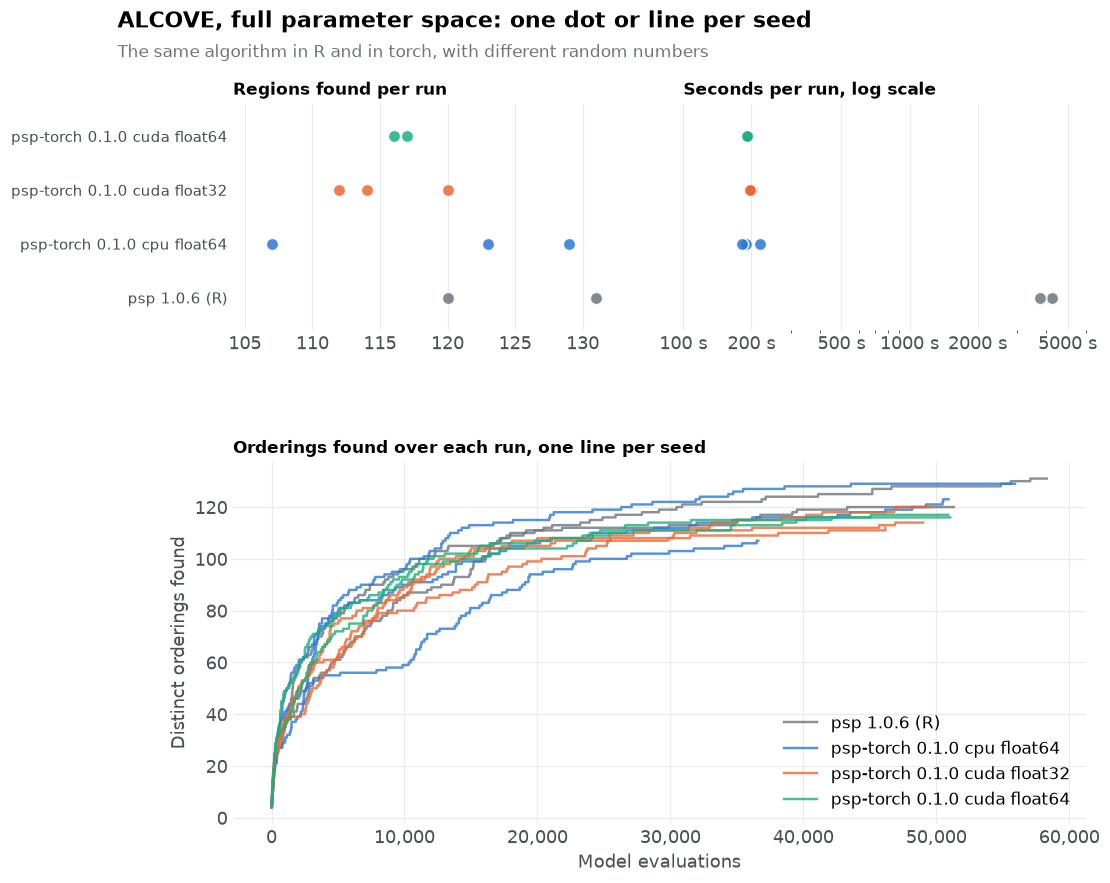

In [15]:
curves = read("alcove_discovery")
fig = plt.figure(figsize=(10, 8.5))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.6], hspace=0.45, wspace=0.12)
strips = [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])]
for ax, key, title in zip(strips, ["patterns", "seconds"], ["Regions found per run", "Seconds per run, log scale"]):
    for i, b in enumerate(alcove_builds):
        d = alcove[alcove.build == b]
        ax.plot(d[key], [i] * len(d), "o", markersize=8, color=alcove_colours[b], markeredgecolor="white", alpha=0.85)
    ax.set_yticks(range(len(alcove_builds)), alcove_builds, fontsize=10)
    ax.set_ylim(-0.6, len(alcove_builds) - 0.4)
    ax.grid(axis="y", visible=False)
    ax.set_title(title, loc="left", fontsize=11)
strips[0].margins(x=0.12)
strips[1].set_xscale("log")
strips[1].set_xlim(100, 6000)
strips[1].set_xticks([100, 200, 500, 1000, 2000, 5000], ["100 s", "200 s", "500 s", "1000 s", "2000 s", "5000 s"])
strips[1].xaxis.set_minor_formatter(plt.NullFormatter())
strips[1].set_yticklabels([])
ax = fig.add_subplot(grid[1, :])
for b in alcove_builds:
    for k, (seed, d) in enumerate(curves[curves.build == b].groupby("seed")):
        ax.step(d.evaluations, d.patterns, where="post", color=alcove_colours[b], linewidth=1.6, alpha=0.8,
                label=b if k == 0 else None)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_xlabel("Model evaluations")
ax.set_ylabel("Distinct orderings found")
ax.set_title("Orderings found over each run, one line per seed", loc="left", fontsize=11)
ax.legend(loc="lower right")
fig.suptitle("ALCOVE, full parameter space: one dot or line per seed", x=0.02, ha="left", fontweight="bold")
fig.text(0.02, 0.93, "The same algorithm in R and in torch, with different random numbers", color="#6c757d", fontsize=11)
plt.show()

Do the builds find the *same* orderings? Pooling the three seeds of each build:

In [16]:
found = read("alcove_patterns").dropna(subset=["order"])   # NaN patterns are not orderings
sets = {b: set(found[found.build == b].order) for b in alcove_builds}
everywhere = set.intersection(*sets.values())
anywhere = set.union(*sets.values())
per_seed = found.groupby(["build", "seed"]).order.nunique().unstack("seed").loc[alcove_builds]
per_seed.columns = [f"seed {c}" for c in per_seed.columns]
per_seed = per_seed.map(lambda v: "–" if pd.isna(v) else int(v))
overlap = pd.DataFrame({
    **per_seed,
    "all seeds pooled": [len(sets[b]) for b in alcove_builds],
    "found by every build": [len(sets[b] & everywhere) for b in alcove_builds],
    "found by this build only": [len(sets[b] - set.union(*(sets[o] for o in alcove_builds if o != b))) for b in alcove_builds],
}, index=alcove_builds)
display(overlap)
r_build_a = next((b for b in alcove_builds if not b.startswith("psp-torch")), None)
cpu_build_a = next((b for b in alcove_builds if b.endswith("cpu float64")), alcove_builds[-1])
if r_build_a is not None:
    shared = sets[r_build_a] & sets[cpu_build_a]
    display(Markdown(f"""
Across all builds and seeds, {len(anywhere)} distinct orderings turned up, and {len(everywhere)} of them were found by every build. The R package and the port on the CPU share {len(shared)} orderings: {len(sets[r_build_a] - sets[cpu_build_a])} were found by R only and {len(sets[cpu_build_a] - sets[r_build_a])} by the port only. The orderings only one build found are the rare ones, each produced by a few parameter sets; with the same algorithm and different random numbers that is what repeated runs look like, and the [recipe](recipe-alcove.ipynb) shows the same picture across trial orders. One difference is systematic: at the lower bound of the specificity with a large association learning rate the weights diverge, catlearn's exponential ratio rule overflows and R gets `NaN` curves, which `pspGlobal()` keeps as one `NaN` region; the port computes the same rule as a numerically stable softmax and gets finite curves and ordinary orderings there. Those parameter sets are {nan_share[r_build_a]:.0%} of R's evaluations.
"""))

,seed 1,seed 2,seed 3,all seeds pooled,found by every build,found by this build only
psp 1.0.6 (R),–,115,114,121,110,3
psp-torch 0.1.0 cpu float64,123,129,107,141,110,14
psp-torch 0.1.0 cuda float32,120,114,112,129,110,3
psp-torch 0.1.0 cuda float64,116,–,117,122,110,0



Across all builds and seeds, 151 distinct orderings turned up, and 110 of them were found by every build. The R package and the port on the CPU share 116 orderings: 5 were found by R only and 25 by the port only. The orderings only one build found are the rare ones, each produced by a few parameter sets; with the same algorithm and different random numbers that is what repeated runs look like, and the [recipe](recipe-alcove.ipynb) shows the same picture across trial orders. One difference is systematic: at the lower bound of the specificity with a large association learning rate the weights diverge, catlearn's exponential ratio rule overflows and R gets `NaN` curves, which `pspGlobal()` keeps as one `NaN` region; the port computes the same rule as a numerically stable softmax and gets finite curves and ordinary orderings there. Those parameter sets are 7% of R's evaluations.


In [17]:
def med(b, key):
    return alcove[alcove.build == b][key].median()


lines = []
if r_build_a is not None:
    for b in [x for x in alcove_builds if x.startswith("psp-torch")]:
        lines.append(f"- **{b}**: {med(b, 'seconds') / 60:.1f} minutes per run against {med(r_build_a, 'seconds') / 60:.1f} for R, "
                     f"{med(r_build_a, 'seconds') / med(b, 'seconds'):.1f}× faster, finding a median of {med(b, 'patterns'):.0f} regions "
                     f"against {med(r_build_a, 'patterns'):.0f}.")
display(Markdown(f"""
What the numbers say:

{chr(10).join(lines)}

- With the learning rates free up to 1, ALCOVE produces many more orderings than within the ranges of Pitt et al. (where the recipe found 44), and the search does not fill them all within 1,000 iterations: a long tail of rare orderings keeps the run at the cap. The number of regions a run finds is a property of the sampler and the model, not of the implementation, so R and the port agree within the spread between seeds. R's counts include its NaN patterns (the "of which" column): counting orderings only, its runs found {' and '.join(str(int(n)) for n in found[found.build == r_build_a].groupby('seed').order.nunique())}.
- The port's advantage is the batched model: every iteration evaluates all the orderings still filling in one call, while the R package evaluates them one at a time. With more orderings in play, the batches are larger and the gap grows.
- The GPU neither gains nor loses here, as the device study predicts: the batches of a run are a few dozen to a couple of hundred parameter sets, where this card is about even with the CPU in either precision. A larger card would move the ALCOVE runs ahead of the CPU; see the device study for where the crossover sits.
"""))


What the numbers say:

- **psp-torch 0.1.0 cpu float64**: 3.2 minutes per run against 67.3 for R, 21.3× faster, finding a median of 123 regions against 126.
- **psp-torch 0.1.0 cuda float32**: 3.3 minutes per run against 67.3 for R, 20.4× faster, finding a median of 114 regions against 126.
- **psp-torch 0.1.0 cuda float64**: 3.2 minutes per run against 67.3 for R, 21.0× faster, finding a median of 116 regions against 126.

- With the learning rates free up to 1, ALCOVE produces many more orderings than within the ranges of Pitt et al. (where the recipe found 44), and the search does not fill them all within 1,000 iterations: a long tail of rare orderings keeps the run at the cap. The number of regions a run finds is a property of the sampler and the model, not of the implementation, so R and the port agree within the spread between seeds. R's counts include its NaN patterns (the "of which" column): counting orderings only, its runs found 115 and 114.
- The port's advantage is the batched model: every iteration evaluates all the orderings still filling in one call, while the R package evaluates them one at a time. With more orderings in play, the batches are larger and the gap grows.
- The GPU neither gains nor loses here, as the device study predicts: the batches of a run are a few dozen to a couple of hundred parameter sets, where this card is about even with the CPU in either precision. A larger card would move the ALCOVE runs ahead of the CPU; see the device study for where the crossover sits.


## How this was measured

In [18]:
def r_version():
    import glob
    for rscript in ["Rscript", *sorted(glob.glob("C:/Program Files/R/*/bin/Rscript.exe"), reverse=True)]:
        try:
            out = subprocess.run([rscript, "-e", "cat(R.version.string)"], capture_output=True, text=True, timeout=60)
            if out.stdout.strip():
                return out.stdout.strip()
        except Exception:
            continue
    return "not found"


pd.DataFrame({
    "Environment": ["Machine", "CPU threads", "GPU", "torch", "Python", "R", "Builds"],
    " ": [f"{platform.node()}, {platform.system()} {platform.release()}", torch.get_num_threads(),
          torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none", torch.__version__,
          platform.python_version(), r_version(), ", ".join(builds)],
}).set_index("Environment")

,
Environment,
Machine,"DCP-UKT-PC010, Windows 11"
CPU threads,12
GPU,NVIDIA T400 4GB
torch,2.11.0+cu128
Python,3.12.4
R,R version 4.4.0 (2024-04-24 ucrt)
Builds,"psp 1.0.6 (R), psp-torch 0.1.0 cpu, psp-torch ..."


| Workload | Model | Settings |
| --- | --- | --- |
| Test-suite model | the model from the test suite: distances to 100 points, 5 parameters | population 10, radius 1, cap 1,000, 10 starting points, 10 seeds |
| 100 regions | cheap Voronoi model: squared distance to 100 random centres, 5 parameters | population 20, radius 0.3, cap 1,500, one start at 0.5, 5 seeds |
| 300 and 1,000 regions | the same cheap model with 300 or 1,000 centres | 100 iterations, population never reached, radius 0.3, 3 seeds |
| Overhead | returns its parameters; discretize bins them into 1,024 grid cells | 150 iterations, 3 repeats |
| Discovery | cheap Voronoi model, 50 centres, 3 parameters | population 10, radius 0.3, cap 500, 30 seeds |

Times are wall-clock seconds with `quiet=True`, each build in its own process, nothing else running. The R package was built from the source in `psp-reference/` (psp 1.0.6) and run with the R package's own `benchmark.R` and `experiments.R`, copied unchanged to `benchmarks/r/`. The Voronoi centres and the test model's positions are drawn with each language's own random number generator, so they differ between R and torch, with the same structure. To re-measure:

```sh
uv run python benchmarks/compare.py --r-library <library with psp 1.0.6> --devices cpu,cuda --rowwise
uv run python benchmarks/devices.py
uv run python benchmarks/alcove_benchmark.py --device cpu
uv run python benchmarks/alcove_benchmark.py --device cuda --dtype float32
Rscript benchmarks/r/alcove_benchmark.R <library> "psp 1.0.6 (R)" 1,2,3 <scratch dir>
uv run python benchmarks/alcove_benchmark.py --import-r <scratch dir>
uv run python notebooks/execute.py benchmarks.ipynb
```